Predict future averge price of Cereals and Tubers monthly by using SARIMAX model and Linear Regression Model
* According to the result, the Linear Regression Model is better than SARIMAX model.
* As the result, the price of rice is mostly effect on the price of cereals and tubers.

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2013-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DCTM = data.copy()
DCTM = DCTM[DCTM['category']=='cereals and tubers']
DCTM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
6,1/15/2008,Magway,Magway,Magway,cereals and tubers,Potatoes,Potatoes,NaN,KG,actual,Retail,MMK,242.42,0.1362
7,1/15/2008,Magway,Magway,Magway,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,604.17,0.3394
9,1/15/2008,Magway,Magway,Yenanchaung,cereals and tubers,Potatoes,Potatoes,NaN,KG,actual,Retail,MMK,363.64,0.2043
10,1/15/2008,Magway,Magway,Yenanchaung,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,900.00,0.5056


In [13]:
DCTM = DCTM[['date', 'price']]
DCTM['date'] = pd.to_datetime(DCTM['date'])
mask = (DCTM['date']>=obv_st_date) & (DCTM['date']<=obv_end_date)
DCTM = DCTM.loc[mask]
DCTM = DCTM.set_index('date')
DCTM.head()

,price
date,
2008-01-15,400.00
2008-01-15,242.42
2008-01-15,604.17
2008-01-15,363.64
2008-01-15,900.00


In [14]:
DCTM = DCTM.resample('MS').mean()
DCTM.head()

,price
date,
2008-01-01,458.406563
2008-02-01,452.949333
2008-03-01,416.180625
2008-04-01,457.803333
2008-05-01,500.172105


In [15]:
DCTM.shape

(169, 1)

In [16]:
price = DCTM['price']
date = DCTM.index

##### Normalization Data

In [17]:
scaler = MinMaxScaler()

In [18]:
DCTM_nor = scaler.fit_transform(DCTM)
DCTM_nor = pd.DataFrame(DCTM_nor)
DCTM_nor.head()

,0
0,0.252215
1,0.241244
2,0.167329
3,0.251002
4,0.336175


In [19]:
DCTM_nor['date']=date
DCTM_nor = DCTM_nor.set_index('date')
DCTM_nor.columns=['price']
DCTM_nor.head()

,price
date,
2008-01-01,0.252215
2008-02-01,0.241244
2008-03-01,0.167329
2008-04-01,0.251002
2008-05-01,0.336175


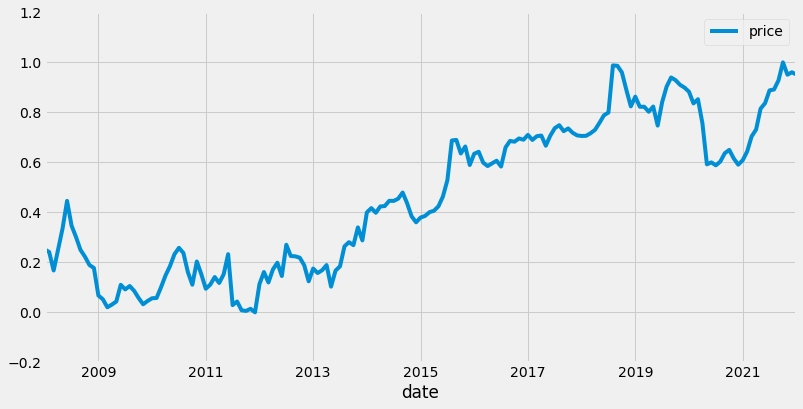

In [20]:
plt.rcParams.update({'figure.figsize': (12,6)})
DCTM_nor.plot(grid=True)
plt.show()

It has upward trend. So it has difference = 1

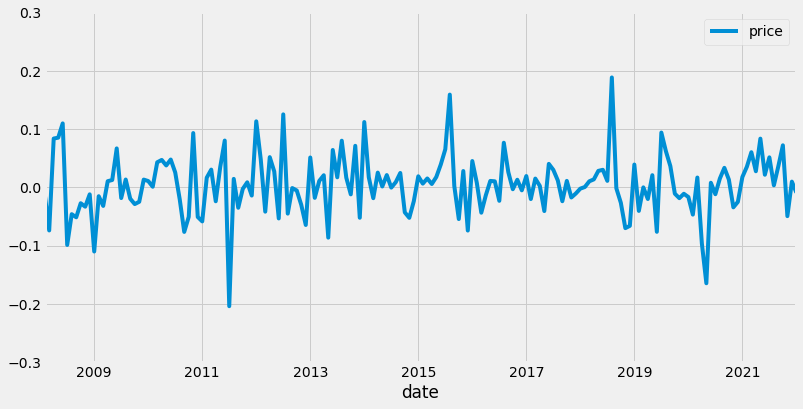

In [21]:
DCTM_nor_diff1 = DCTM_nor.diff(1).dropna()
plt.rcParams.update({'figure.figsize': (12,6)})
DCTM_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [22]:
RW_DCTM= adfuller(DCTM_nor_diff1)
RW_DCTM[1] # print P-value. If p-value<5%, reject null hypothesis

0.00026808414910973024

##### Plotting ACF and PACF

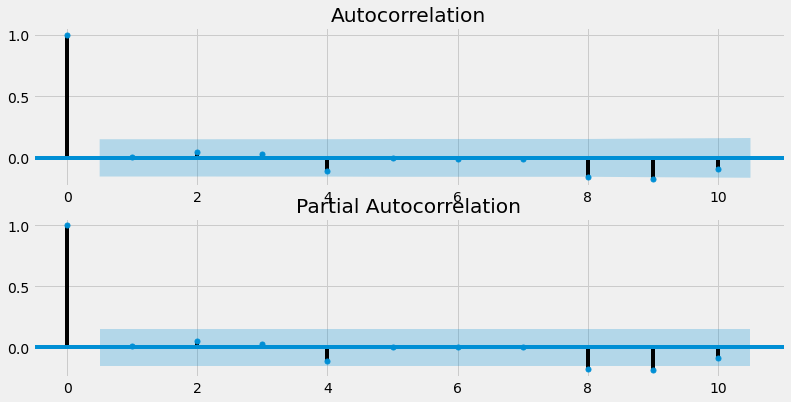

In [23]:
fig, axes=plt.subplots(2,1)
plot_acf(DCTM_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DCTM_nor_diff1, lags=10, ax=axes[1])
plt.show()

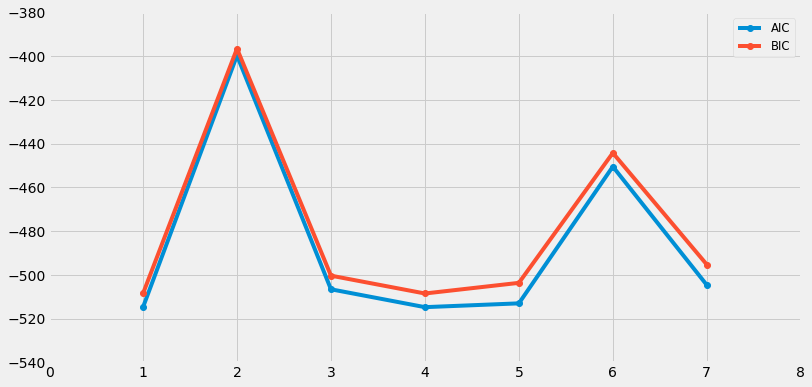

In [24]:
AIC, BIC = AIC_BIC_withOrderRange(DCTM_nor_diff1, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [25]:
AIC, BIC

(array([-516.73877362, -514.77929593, -399.69898908, -506.61680001,
        -514.78373643, -513.04717462, -450.50846205, -504.65804422]),
 array([-513.61480964, -508.53136797, -396.58099526, -500.38081238,
        -508.53580847, -503.67528268, -444.27247443, -495.30406278]))

We will run again 1:(0,0,1), 4:(1,0,0), 5:(1,0,1)

In [26]:
mod_orders = [
    (0,0,1),
    (1,0,0),
    (1,0,1),
]

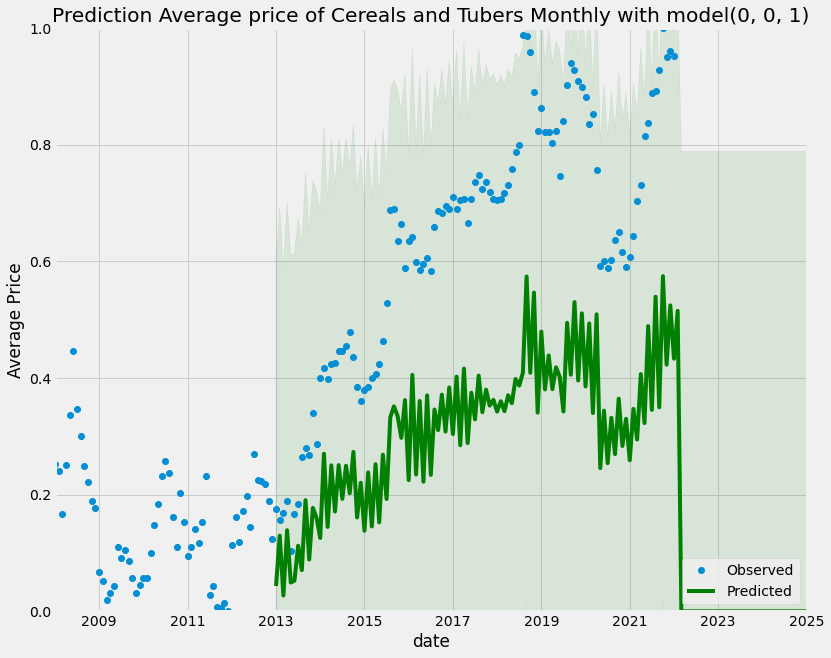

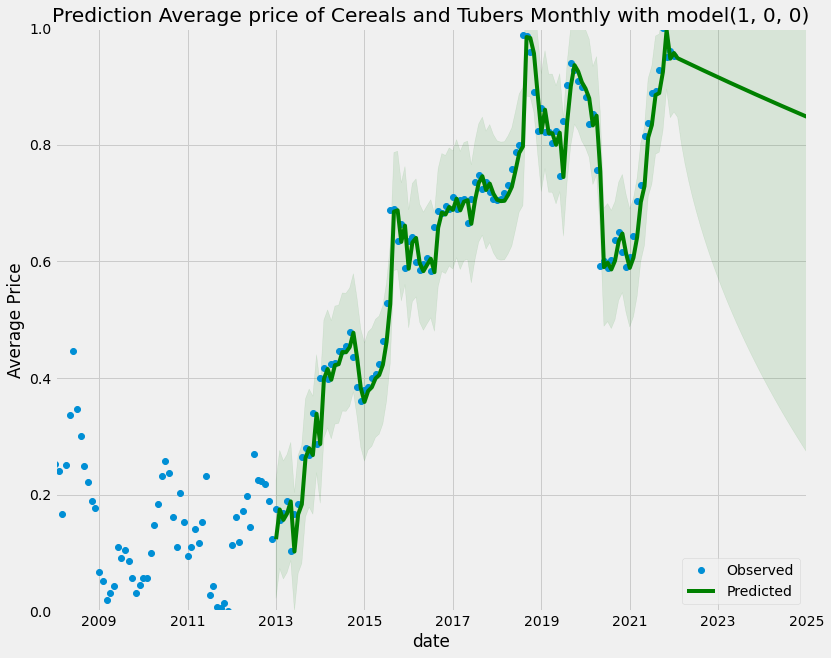

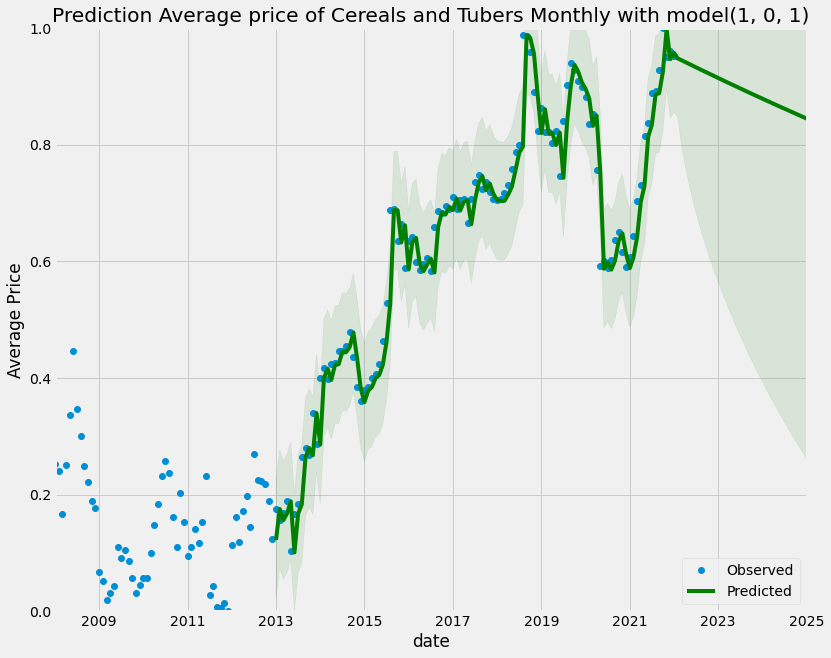

In [27]:
DCTM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DCTM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Cereals and Tubers Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DCTM_models.append(model)

Now we choose (0,1,0)

In [28]:
DCTM_model = DCTM_models[2]

In [29]:
DCTM_pred_normalized  = DCTM_model.predict(pred_st_date, pred_end_date)
DCTM_pred_normalized 

2013-01-01    0.122554
2013-02-01    0.175502
2013-03-01    0.156393
2013-04-01    0.167894
2013-05-01    0.188717
                ...   
2024-09-01    0.856074
2024-10-01    0.853257
2024-11-01    0.850450
2024-12-01    0.847652
2025-01-01    0.844864
Freq: MS, Length: 145, dtype: float64

We need to un-normalized the predicted value to get actual price

In [30]:
mask = (DCTM_nor.index>=pred_st_date) & (DCTM_nor.index<=pred_end_date)
DCTM_pred = DCTM_nor.loc[mask]
DCTM_pred

,price
date,
2013-01-01,0.175203
2013-02-01,0.157214
2013-03-01,0.168250
2013-04-01,0.188988
2013-05-01,0.102757
...,...
2021-09-01,0.927949
2021-10-01,1.000000
2021-11-01,0.950639


In [31]:
pred_date = DCTM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=144, freq='MS')

In [32]:
DCTM_pred_normalized_df = pd.DataFrame(DCTM_pred_normalized)
DCTM_pred_normalized_df = DCTM_pred_normalized_df[:-1] # the last index doesn't need
DCTM_pred_normalized_df

,0
2013-01-01,0.122554
2013-02-01,0.175502
2013-03-01,0.156393
2013-04-01,0.167894
2013-05-01,0.188717
...,...
2024-08-01,0.858899
2024-09-01,0.856074
2024-10-01,0.853257
2024-11-01,0.850450


In [33]:
DCTM_pred_act = scaler.inverse_transform(DCTM_pred_normalized_df)
DCTM_pred_act_df = pd.DataFrame(DCTM_pred_act)
DCTM_pred_act_df['date'] = pred_date
DCTM_pred_act_df.columns = ['Predicted Price', 'date']
DCTM_pred_act_df.set_index('date', inplace=True)
DCTM_pred_act_df

,Predicted Price
date,
2013-01-01,393.907975
2013-02-01,420.246350
2013-03-01,410.740680
2013-04-01,416.461803
2013-05-01,426.819866
...,...
2024-08-01,760.196876
2024-09-01,758.791285
2024-10-01,757.390318


In [34]:
mask = (DCTM.index>=pred_st_date) & (DCTM.index<=pred_end_date)
DCTM_Act = DCTM.loc[mask]
DCTM_Act

,price
date,
2013-01-01,420.097872
2013-02-01,411.149130
2013-03-01,416.639130
2013-04-01,426.954783
2013-05-01,384.060000
...,...
2021-09-01,794.544940
2021-10-01,830.386364
2021-11-01,805.831954


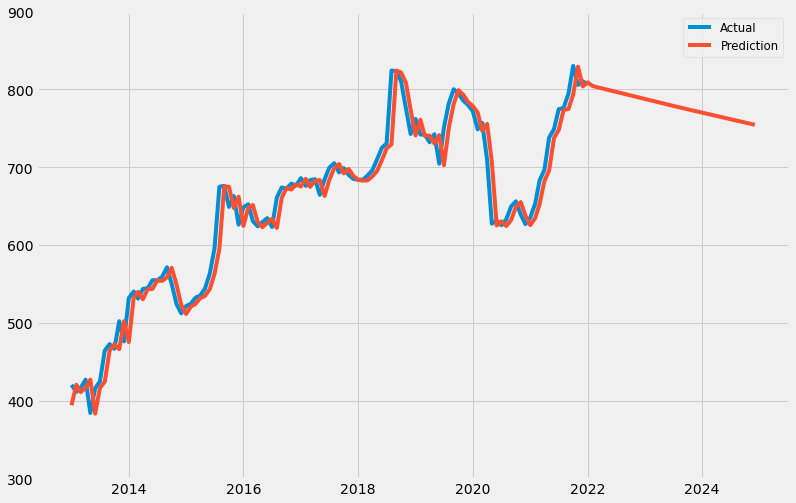

In [35]:
plt.figure(figsize=(12,8))
plt.plot(DCTM_Act, label="Actual")
plt.plot(DCTM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [36]:
temp_df = DCTM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.252215
1,2008-02-01,0.241244
2,2008-03-01,0.167329
3,2008-04-01,0.251002
4,2008-05-01,0.336175
...,...,...
164,2021-09-01,0.927949
165,2021-10-01,1.000000
166,2021-11-01,0.950639
167,2021-12-01,0.960439


In [37]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2008-01-01  0.252215  1199145600000000000
 1   2008-02-01  0.241244  1201824000000000000
 4   2008-05-01  0.336175  1209600000000000000
 5   2008-06-01  0.445786  1212278400000000000
 6   2008-07-01  0.347011  1214870400000000000
 ..         ...       ...                  ...
 164 2021-09-01  0.927949  1630454400000000000
 165 2021-10-01  1.000000  1633046400000000000
 166 2021-11-01  0.950639  1635724800000000000
 167 2021-12-01  0.960439  1638316800000000000
 168 2022-01-01  0.951379  1640995200000000000
 
 [136 rows x 3 columns],
           date     price                 time
 2   2008-03-01  0.167329  1204329600000000000
 3   2008-04-01  0.251002  1207008000000000000
 8   2008-09-01  0.249640  1220227200000000000
 10  2008-11-01  0.189231  1225497600000000000
 11  2008-12-01  0.177263  1228089600000000000
 15  2009-04-01  0.030721  1238544000000000000
 20  2009-09-01  0.085668  1251763200000000000
 27  2010-04-01  0.147274  127008

In [38]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1199145600000000000],
        [1201824000000000000],
        [1209600000000000000],
        [1212278400000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1222819200000000000],
        [1230768000000000000],
        [1233446400000000000],
        [1235865600000000000]], dtype=int64),
 array([0.2522148 , 0.24124422, 0.33617542, 0.44578642, 0.34701053,
        0.30101605, 0.22241199, 0.067231  , 0.05204284, 0.02019831]))

In [39]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1204329600000000000],
        [1207008000000000000],
        [1220227200000000000],
        [1225497600000000000],
        [1228089600000000000],
        [1238544000000000000],
        [1251763200000000000],
        [1270080000000000000],
        [1275350400000000000],
        [1277942400000000000]], dtype=int64),
 array([0.16732866, 0.25100214, 0.24963962, 0.18923057, 0.17726323,
        0.03072104, 0.08566844, 0.14727427, 0.23246987, 0.25798006]))

In [40]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [41]:
DCTM_linreg = LinearRegression().fit(X_train, y_train)

In [42]:
print('linear model coeff or slope (w): {}'.format(DCTM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DCTM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DCTM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DCTM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [2.12394121e-18]
linear model intercept (b): -2.554
R-squared score (training): 0.795
R-squared score (test): 0.788


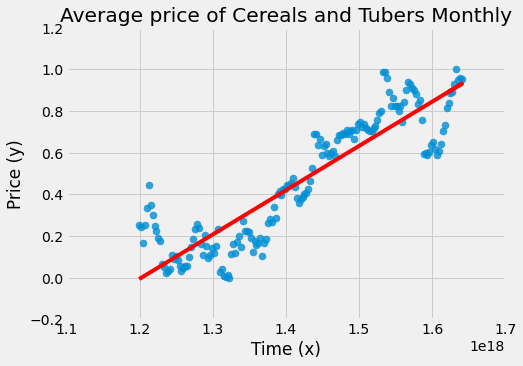

In [43]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DCTM_linreg.coef_ * X + DCTM_linreg.intercept_, 'r-')
plt.title('Average price of Cereals and Tubers Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [44]:
DCTM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DCTM_linear_predict['time'] = DCTM_linear_predict['date'].apply(lambda x: x.value)
DCTM_linear_predict

,date,time
0,2013-01-01,1356998400000000000
1,2013-02-01,1359676800000000000
2,2013-03-01,1362096000000000000
3,2013-04-01,1364774400000000000
4,2013-05-01,1367366400000000000
...,...,...
140,2024-09-01,1725148800000000000
141,2024-10-01,1727740800000000000
142,2024-11-01,1730419200000000000
143,2024-12-01,1733011200000000000


In [45]:
time_predict = np.array(DCTM_linear_predict['time']).reshape((-1, 1))
DCTM_linear_predict['price'] = DCTM_linreg.predict(time_predict)
DCTM_linear_predict

,date,time,price
0,2013-01-01,1356998400000000000,0.328571
1,2013-02-01,1359676800000000000,0.334260
2,2013-03-01,1362096000000000000,0.339398
3,2013-04-01,1364774400000000000,0.345087
4,2013-05-01,1367366400000000000,0.350592
...,...,...,...
140,2024-09-01,1725148800000000000,1.110501
141,2024-10-01,1727740800000000000,1.116006
142,2024-11-01,1730419200000000000,1.121695
143,2024-12-01,1733011200000000000,1.127200


In [46]:
DCTM_linear_normalized_predict = DCTM_linear_predict.copy()
DCTM_linear_normalized_predict = DCTM_linear_normalized_predict[['date', 'price']]
DCTM_linear_normalized_predict.set_index('date', inplace=True)
DCTM_linear_normalized_predict

,price
date,
2013-01-01,0.328571
2013-02-01,0.334260
2013-03-01,0.339398
2013-04-01,0.345087
2013-05-01,0.350592
...,...
2024-09-01,1.110501
2024-10-01,1.116006
2024-11-01,1.121695


##### Unnormalized the data

In [47]:
DCTM_pred_act_linear = scaler.inverse_transform(DCTM_linear_normalized_predict)
DCTM_pred_act_linear_df = pd.DataFrame(DCTM_pred_act_linear)
DCTM_pred_act_linear_df['date'] = DCTM_linear_predict['date']
DCTM_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DCTM_pred_act_linear_df.set_index('date', inplace=True)
DCTM_pred_act_linear_df

,Predicted Price (KG)
date,
2013-01-01,496.389339
2013-02-01,499.219170
2013-03-01,501.775146
2013-04-01,504.604976
2013-05-01,507.343522
...,...
2024-09-01,885.354104
2024-10-01,888.092650
2024-11-01,890.922480
